<a href="https://colab.research.google.com/github/hsarrah-create/Assignment-1/blob/main/Ass%201%2B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from google.colab import drive, files

drive.mount('/content/drive')
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))

df["Timestamp"] = pd.to_datetime(
    df["Timestamp"], errors="coerce"
)
df = df.sort_values(["Case ID", "Event Order"])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/derived_event_log_complaint_management.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

Dataset loaded successfully!
Rows: 85284
Columns: 5


,Case ID,Activity,Timestamp,Timestamp Type,Event Order
0,6168884918,Order Placed,2024-09-10 23:38:00,Observed,1
1,6168884918,Ready Marked - Correctly,2024-09-10 23:56:21,Derived from Order Placed At + KPT,2
2,6168884918,Order Status - Delivered,NaT,Not available in source,3
3,6168884918,No Complaint,NaT,Not available in source,4
4,6170707559,Order Placed,2024-09-10 23:34:00,Observed,1


In [ ]:
import pandas as pd

file_path = "/content/drive/MyDrive/derived_event_log_complaint_management.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

Dataset loaded successfully!
Rows: 85284
Columns: 5


,Case ID,Activity,Timestamp,Timestamp Type,Event Order
0,6168884918,Order Placed,2024-09-10 23:38:00,Observed,1
1,6168884918,Ready Marked - Correctly,2024-09-10 23:56:21,Derived from Order Placed At + KPT,2
2,6168884918,Order Status - Delivered,NaT,Not available in source,3
3,6168884918,No Complaint,NaT,Not available in source,4
4,6170707559,Order Placed,2024-09-10 23:34:00,Observed,1


In [ ]:
print(df.columns.tolist())

print("\nActivity counts:")
print(df["Activity"].value_counts())

['Case ID', 'Activity', 'Timestamp', 'Timestamp Type', 'Event Order']

Activity counts:
Activity
Order Placed                                    21321
Order Status - Delivered                        21131
No Complaint                                    20852
Ready Marked - Correctly                        19087
Ready Marked - Incorrectly                       1895
Ready Marked - Missed                             339
Order Status - Rejected                           158
Complaint - Non-refunded complaint                157
Complaint - Poor taste or quality                 120
Complaint - Poor packaging or spillage            104
Complaint - Wrong item(s) delivered                48
Complaint - Item(s) missing or not delivered       40
Order Status - Returned                            25
Order Status - Return cancelled                     3
Order Status - Picked up                            3
Order Status - Timed out                            1
Name: count, dtype: int64


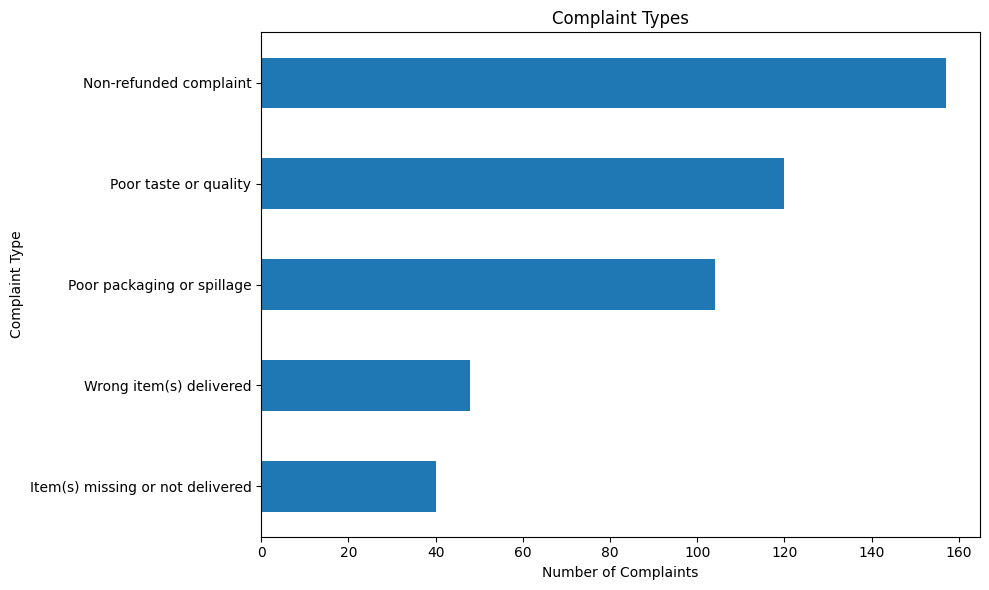

In [ ]:
import matplotlib.pyplot as plt

complaint_activities = [
    "Complaint - Non-refunded complaint",
    "Complaint - Poor taste or quality",
    "Complaint - Poor packaging or spillage",
    "Complaint - Wrong item(s) delivered",
    "Complaint - Item(s) missing or not delivered"
]

complaints = df[df["Activity"].isin(complaint_activities)]

complaint_counts = complaints["Activity"].value_counts()

complaint_counts.index = [
    x.replace("Complaint - ", "")
    for x in complaint_counts.index
]

plt.figure(figsize=(10, 6))
complaint_counts.sort_values().plot(kind="barh")

plt.title("Complaint Types")
plt.xlabel("Number of Complaints")
plt.ylabel("Complaint Type")

plt.tight_layout()
plt.show()

In [ ]:
# Prepare Order Placed events
orders = df[df["Activity"] == "Order Placed"].copy()

# Convert Timestamp to datetime
orders["Timestamp"] = pd.to_datetime(
    orders["Timestamp"],
    errors="coerce"
)

# Keep orders with valid timestamps
orders = orders.dropna(subset=["Timestamp"])

# Extract month
orders["Month"] = orders["Timestamp"].dt.to_period("M")

# Number of orders per month
monthly_orders = orders.groupby("Month")["Case ID"].nunique()

print("Monthly Orders:")
print(monthly_orders)

Monthly Orders:
Month
2024-09    4241
2024-10    4277
2024-11    4491
2024-12    4301
2025-01    4011
Freq: M, Name: Case ID, dtype: int64


In [ ]:
# Complaint events
complaints = df[
    df["Activity"].isin(complaint_activities)
    ].copy()

# Get the Order Placed timestamp for each Case ID
order_dates = orders.set_index("Case ID")["Timestamp"]

# Attach the order date to each complaint
complaints["Order Timestamp"] = complaints["Case ID"].map(order_dates)

# Extract month
complaints["Month"] = complaints["Order Timestamp"].dt.to_period("M")

# Number of complaint cases per month
monthly_complaints = complaints.groupby("Month")["Case ID"].nunique()

# Calculate complaint rate
monthly_complaint_rate = (
    monthly_complaints / monthly_orders * 100
).fillna(0)

print("Monthly Complaints:")
print(monthly_complaints)

print("\nMonthly Complaint Rate (%):")
print(monthly_complaint_rate)

Monthly Complaints:
Month
2024-09     58
2024-10    104
2024-11    125
2024-12     89
2025-01     93
Freq: M, Name: Case ID, dtype: int64

Monthly Complaint Rate (%):
Month
2024-09    1.367602
2024-10    2.431611
2024-11    2.783344
2024-12    2.069286
2025-01    2.318624
Freq: M, Name: Case ID, dtype: float64


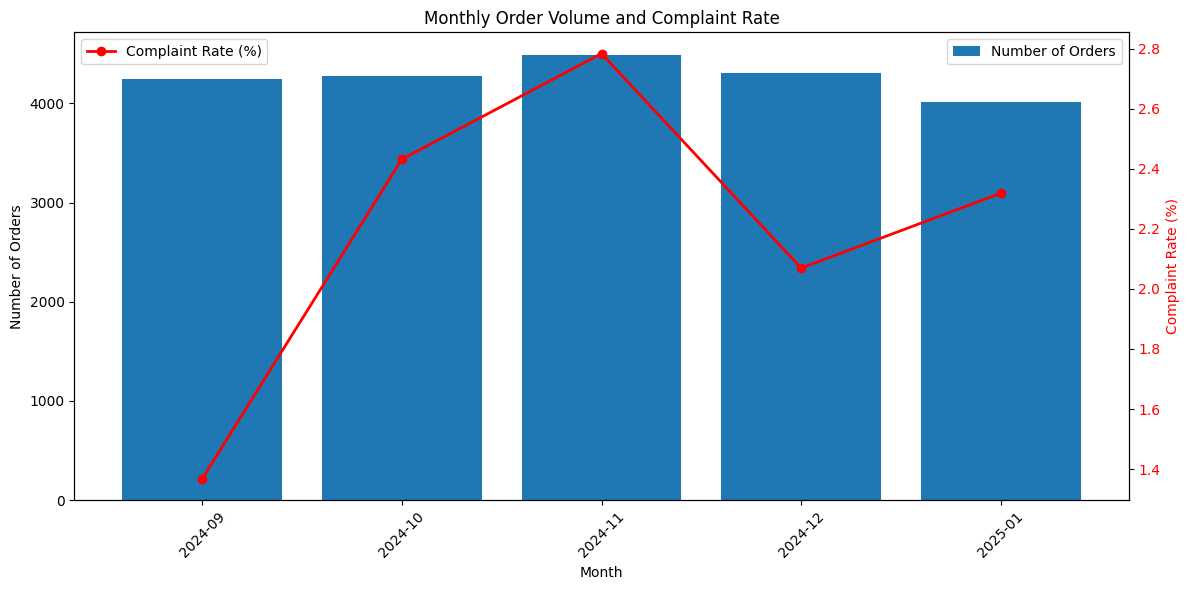

In [ ]:
import matplotlib.pyplot as plt

months = monthly_orders.index.astype(str)

fig, ax1 = plt.subplots(figsize=(12, 6))

# Number of orders
ax1.bar(
    months,
    monthly_orders.values,
    label="Number of Orders"
)

ax1.set_xlabel("Month")
ax1.set_ylabel("Number of Orders")
ax1.tick_params(axis="x", rotation=45)
ax1.legend(loc='upper right') # Added for completeness

# Complaint rate
ax2 = ax1.twinx()

ax2.plot(
    months,
    monthly_complaint_rate.values,
    marker="o",
    linewidth=2,
    color='red',
    label="Complaint Rate (%)"
)

ax2.set_ylabel("Complaint Rate (%)", color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.legend(loc='upper left') # Added for completeness

plt.title("Monthly Order Volume and Complaint Rate")
plt.tight_layout()
plt.show()

In [ ]:
print("=== Timestamp Type ===")
print(df["Timestamp Type"].value_counts(dropna=False))

print("\n=== Events with Timestamp ===")

timed_events = df[df["Timestamp"].notna()].copy()

print(
    timed_events[
            ["Case ID", "Activity", "Timestamp", "Timestamp Type", "Event Order"]
                ].head(20).to_string(index=False)
                )

=== Timestamp Type ===
Timestamp Type
Not available in source               42642
Observed                              21321
Derived from Order Placed At + KPT    21321
Name: count, dtype: int64

=== Events with Timestamp ===
   Case ID                   Activity           Timestamp                     Timestamp Type  Event Order
6168884918               Order Placed 2024-09-10 23:38:00                           Observed            1
6168884918   Ready Marked - Correctly 2024-09-10 23:56:21 Derived from Order Placed At + KPT            2
6170707559               Order Placed 2024-09-10 23:34:00                           Observed            1
6170707559   Ready Marked - Correctly 2024-09-10 23:50:57 Derived from Order Placed At + KPT            2
6169375019               Order Placed 2024-09-10 15:52:00                           Observed            1
6169375019   Ready Marked - Correctly 2024-09-10 16:06:03 Derived from Order Placed At + KPT            2
6151677434               Order 

In [ ]:
# Get Order Placed timestamps
order_time = (
    df[df["Activity"] == "Order Placed"]
        [["Case ID", "Timestamp"]]
            .rename(columns={"Timestamp": "Order_Placed_Time"})
)

# Get Ready Marked timestamps
ready_activities = [
    "Ready Marked - Correctly",
    "Ready Marked - Incorrectly",
    "Ready Marked - Missed"
]

ready_time = (
    df[df["Activity"].isin(ready_activities)]
        [["Case ID", "Timestamp"]]
            .rename(columns={"Timestamp": "Ready_Time"})
)

# Merge both timestamps by Case ID
prep = order_time.merge(
    ready_time,
    on="Case ID",
    how="inner"
)

# Calculate preparation time in minutes
prep["Preparation_Time"] = (
    prep["Ready_Time"] - prep["Order_Placed_Time"]
).dt.total_seconds() / 60

# Basic statistics
print("Number of computable cases:", prep["Preparation_Time"].notna().sum())
print("\nPreparation Time Statistics:")
print(prep["Preparation_Time"].describe())

Number of computable cases: 21026

Preparation Time Statistics:
count    21026.000000
mean        17.327310
std          6.283355
min          0.000000
25%         13.366667
50%         16.316667
75%         20.050000
max         90.866667
Name: Preparation_Time, dtype: float64


In [ ]:
# Create preparation-time groups
prep["Preparation_Group"] = pd.cut(
    prep["Preparation_Time"],
    bins=[0, 15, 30, 45, float("inf")],
    labels=["0–15 min", "15–30 min", "30–45 min", ">45 min"],
    include_lowest=True
)

# Get complaint cases
complaint_case_ids = set(
    df[df["Activity"].isin(complaint_activities)]["Case ID"]
)

# Mark whether each order had a complaint
prep["Complaint"] = prep["Case ID"].isin(complaint_case_ids)

# Calculate complaint rate for each preparation-time group
prep_analysis = prep.groupby(
    "Preparation_Group",
    observed=False
).agg(
    Orders=("Case ID", "nunique"),
    Complaints=("Complaint", "sum")
)

prep_analysis["Complaint_Rate"] = (
    prep_analysis["Complaints"] /
    prep_analysis["Orders"] * 100
)

print(prep_analysis)

                   Orders  Complaints  Complaint_Rate
Preparation_Group                                    
0–15 min             8086         171        2.114766
15–30 min           12153         270        2.221674
30–45 min             696          16        2.298851
>45 min                91           6        6.593407


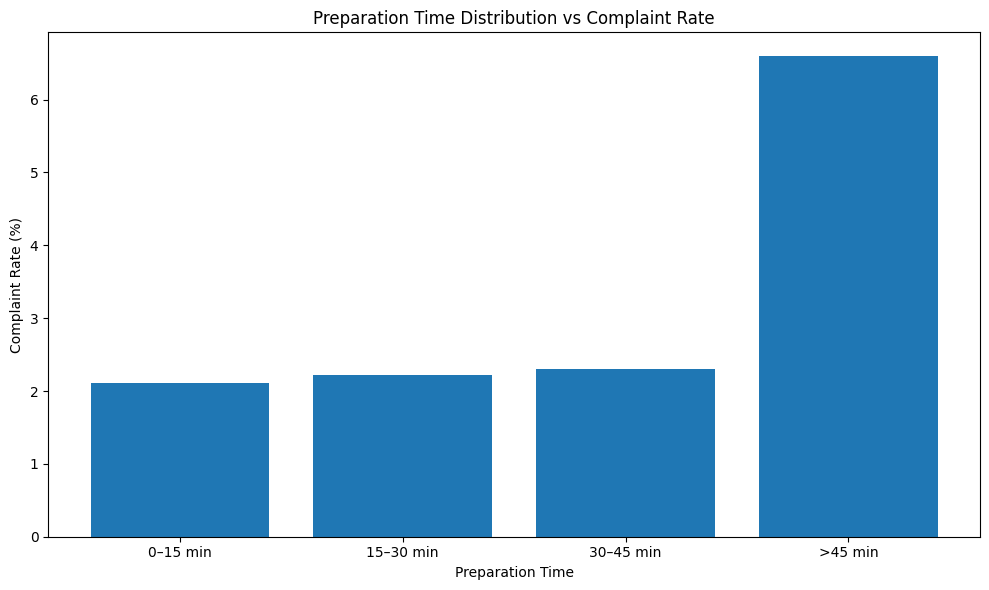

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    prep_analysis.index.astype(str),
    prep_analysis["Complaint_Rate"]
)

plt.title("Preparation Time Distribution vs Complaint Rate")
plt.xlabel("Preparation Time")
plt.ylabel("Complaint Rate (%)")

plt.tight_layout()
plt.show()

In [ ]:
import argparse
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [ ]:
import argparse
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, confusion_matrix)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Ensure Google Drive is mounted in this runtime session
try:
    drive.mount('/content/drive')
except Exception as e:
    print("Drive mount status details:", e)

p = argparse.ArgumentParser()
p.add_argument('--csv', default='/content/drive/MyDrive/derived_event_log_complaint_management.xlsx')
p.add_argument('--out', default='complaint_analysis_outputs')
a, unknown = p.parse_known_args()

out = Path(a.out)
out.mkdir(parents=True, exist_ok=True)

file_path = a.csv
if not Path(file_path).exists():
    raise FileNotFoundError(f"The file {file_path} could not be found. Please ensure that Google Drive is fully mounted and that the path is correct.")

df = pd.read_excel(file_path, dtype={'Case ID': str})

required = {'Case ID', 'Activity', 'Timestamp', 'Event Order'}
if not required.issubset(df.columns):
    raise ValueError('Missing required columns: ' + str(required - set(df.columns)))

df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
order = df[df['Activity'].eq('Order Placed')].drop_duplicates('Case ID').set_index('Case ID')['Timestamp']
ready = df[df['Activity'].str.startswith('Ready Marked', na=False)].drop_duplicates('Case ID').set_index('Case ID')
last = df[df['Activity'].str.startswith('Complaint -', na=False)].drop_duplicates('Case ID').set_index('Case ID')['Activity']

case = pd.DataFrame(index=order.index)
case['prep_minutes'] = (ready['Timestamp'] - order).dt.total_seconds().div(60)
case['readiness'] = ready['Activity'].str.replace('Ready Marked - ', '', regex=False)
case['complaint_type'] = last.str.replace('Complaint - ', '', regex=False)
case['complaint'] = case['complaint_type'].notna().astype(int)
case['prep_missing'] = case['prep_minutes'].isna().astype(int)

# Exploratory root-cause patterns (NOT verified causes).
types = case['complaint_type'].value_counts().rename_axis('complaint_type').reset_index(name='count')
types.to_csv(out/'complaint_types.csv', index=False)

summary = case.groupby('readiness', dropna=False)['complaint'].agg(['count','sum','mean']).reset_index()
summary.to_csv(out/'readiness_complaint_rates.csv', index=False)

case['prep_bin'] = pd.cut(case['prep_minutes'], bins=[-np.inf,10,15,20,25,30,45,np.inf],
                          labels=['<=10','10-15','15-20','20-25','25-30','30-45','>45'])
case.groupby('prep_bin', observed=False)['complaint'].agg(['count','sum','mean']).to_csv(out/'preparation_complaint_rates.csv')

fig, ax = plt.subplots(figsize=(9,4))
ax.bar(types['complaint_type'], types['count'])
ax.tick_params(axis='x', rotation=25)
ax.set_ylabel('Complaints')
fig.tight_layout()
fig.savefig(out/'complaint_types.png', dpi=160)
plt.close(fig)

# Only readiness-stage information is used as input. Do NOT use delivery outcome or complaint category as features.
features = ['prep_minutes','prep_missing','readiness']
X = case[features].copy()
y = case['complaint']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)

pre = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), ['prep_minutes', 'prep_missing']),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), ['readiness'])
])

model = Pipeline([
    ('pre', pre),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

model.fit(X_train, y_train)

train_scores = model.predict_proba(X_train)[:,1]
test_scores = model.predict_proba(X_test)[:,1]

# Demonstration-only cutoffs: training-score quantiles, NOT calibrated complaint probabilities.
q50, q90 = np.quantile(train_scores, [.50,.90])

if q50 == q90:
    print('WARNING: quantile cutoffs coincide; risk groups may be sparse.')

def risk(s):
    return np.where(s>=q90, 'High', np.where(s>=q50, 'Medium','Low'))

res = X_test.copy()
res['actual_complaint'] = y_test
res['model_score'] = test_scores
res['risk_level'] = risk(test_scores)
res['alert'] = res['risk_level'].map({'Low':'No alert','Medium':'Monitor / check readiness','High':'Priority review by human operator'})
res.index.name = 'Case ID'
res.to_csv(out/'test_set_risk_alerts.csv')

metrics = {
    'test_orders': len(y_test),
    'test_complaints': int(y_test.sum()),
    'ROC_AUC': roc_auc_score(y_test, test_scores),
    'Average_Precision': average_precision_score(y_test, test_scores),
    'risk_low_cutoff_score': q50,
    'risk_high_cutoff_score': q90,
    'high_risk_alert_count': int((res['risk_level']=='High').sum()),
    'high_risk_precision': precision_score(y_test, res['risk_level'].eq('High'), zero_division=0),
    'high_risk_recall': recall_score(y_test, res['risk_level'].eq('High'), zero_division=0)
}

pd.Series(metrics, name='value').to_csv(out/'evaluation_metrics.csv', header=True)
res.groupby('risk_level')['actual_complaint'].agg(['count','sum','mean']).to_csv(out/'risk_group_results.csv')

print('Retrospective test metrics:', metrics)
print('Saved outputs to', out.resolve())
print('CAUTION: This script trains an illustrative model; replace with teammate\'s validated model for final integration.')
print('CAUTION: Scores are NOT calibrated probabilities; no live alerts are sent.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Retrospective test metrics: {'test_orders': 4265, 'test_complaints': 94, 'ROC_AUC': np.float64(0.4656289373944715), 'Average_Precision': np.float64(0.021545488299700644), 'risk_low_cutoff_score': np.float64(0.49475512206992606), 'risk_high_cutoff_score': np.float64(0.5280275346246723), 'high_risk_alert_count': 429, 'high_risk_precision': 0.018648018648018648, 'high_risk_recall': 0.0851063829787234}
Saved outputs to /content/complaint_analysis_outputs
CAUTION: This script trains an illustrative model; replace with teammate's validated model for final integration.
CAUTION: Scores are NOT calibrated probabilities; no live alerts are sent.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score

# Four demonstration-only levels: training-score quantiles 50/80/95; NOT calibrated complaint probabilities.
# 'High' metrics include High + Critical, representing all priority alerts.
q50, q80, q95 = np.quantile(train_scores, [.50, .80, .95])

if len(set([q50, q80, q95])) < 3:
    print('WARNING: quantile cutoffs coincide; risk groups may be sparse.')

def risk(s):
    return np.where(s >= q95, 'Critical', np.where(s >= q80, 'High', np.where(s >= q50, 'Medium', 'Low')))

res = X_test.copy()
res['actual_complaint'] = y_test
res['model_score'] = test_scores
res['risk_level'] = risk(test_scores)
res['alert'] = res['risk_level'].map({
    'Low': 'No alert',
    'Medium': 'Monitor / check readiness',
    'High': 'Priority review by human operator',
    'Critical': 'Urgent human review (offline simulation)'
})
res.index.name = 'Case ID'
res.to_csv(out / 'test_set_risk_alerts.csv')

metrics = {
    'test_orders': len(y_test),
    'test_complaints': int(y_test.sum()),
    'ROC_AUC': roc_auc_score(y_test, test_scores),
    'Average_Precision': average_precision_score(y_test, test_scores),
    'risk_low_cutoff_score': q50,
    'risk_high_cutoff_score': q80,
    'risk_critical_cutoff_score': q95,
    'high_risk_alert_count': int(res['risk_level'].isin(['High', 'Critical']).sum()),
    'critical_alert_count': int((res['risk_level'] == 'Critical').sum()),
    'critical_true_complaints': int(((res['risk_level'] == 'Critical') & (res['actual_complaint'] == 1)).sum()),
    'high_risk_precision': precision_score(y_test, res['risk_level'].isin(['High', 'Critical']), zero_division=0),
    'high_risk_recall': recall_score(y_test, res['risk_level'].isin(['High', 'Critical']), zero_division=0)
}

pd.Series(metrics, name='value').to_csv(out / 'evaluation_metrics.csv', header=True)
res.groupby('risk_level')['actual_complaint'].agg(['count', 'sum', 'mean']).to_csv(out / 'risk_group_results.csv')

print('Retrospective test metrics:', metrics)
print('Saved outputs to', out.resolve())
print('CAUTION: This script trains an illustrative model; replace with teammate\'s validated model for final integration.')
print('CAUTION: Scores are NOT calibrated probabilities; no live alerts are sent.')

NameError: name 'train_scores' is not defined

In [ ]:
"""Complaint Management: root-cause exploration, risk stratification, offline alerts.
Run: python complaint_risk_early_warning.py --csv derived_event_log_complaint_management.csv
Dependencies: pandas, numpy, scikit-learn, matplotlib
IMPORTANT: This is a retrospective prototype, NOT a validated live alert system.
"""
import argparse
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score, confusion_matrix
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

p = argparse.ArgumentParser()
p.add_argument('--csv', default='/content/drive/MyDrive/derived_event_log_complaint_management.xlsx')
p.add_argument('--out', default='complaint_analysis_outputs')
# Use parse_known_args() to prevent Jupyter/Colab kernel flags from throwing error
a, unknown = p.parse_known_args()
out = Path(a.out)
out.mkdir(parents=True, exist_ok=True)

df = pd.read_excel(a.csv, dtype={'Case ID': str})
required = {'Case ID', 'Activity', 'Timestamp', 'Event Order'}
if not required.issubset(df.columns):
    raise ValueError('Missing required columns: ' + str(required - set(df.columns)))

df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
order = df[df['Activity'].eq('Order Placed')].drop_duplicates('Case ID').set_index('Case ID')['Timestamp']
ready = df[df['Activity'].str.startswith('Ready Marked', na=False)].drop_duplicates('Case ID').set_index('Case ID')
last = df[df['Activity'].str.startswith('Complaint -', na=False)].drop_duplicates('Case ID').set_index('Case ID')['Activity']

case = pd.DataFrame(index=order.index)
case['prep_minutes'] = (ready['Timestamp'] - order).dt.total_seconds().div(60)
case['readiness'] = ready['Activity'].str.replace('Ready Marked - ', '', regex=False)
case['complaint_type'] = last.str.replace('Complaint - ', '', regex=False)
case['complaint'] = case['complaint_type'].notna().astype(int)
case['prep_missing'] = case['prep_minutes'].isna().astype(int)

# Exploratory root-cause patterns (NOT verified causes).
types = case['complaint_type'].value_counts().rename_axis('complaint_type').reset_index(name='count')
types.to_csv(out / 'complaint_types.csv', index=False)

summary = case.groupby('readiness', dropna=False)['complaint'].agg(['count', 'sum', 'mean']).reset_index()
summary.to_csv(out / 'readiness_complaint_rates.csv', index=False)

case['prep_bin'] = pd.cut(
    case['prep_minutes'],
    bins=[-np.inf, 10, 15, 20, 25, 30, 45, np.inf],
    labels=['<=10', '10-15', '15-20', '20-25', '25-30', '30-45', '>45']
)
case.groupby('prep_bin', observed=False)['complaint'].agg(['count', 'sum', 'mean']).to_csv(out / 'preparation_complaint_rates.csv')

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(types['complaint_type'], types['count'])
ax.tick_params(axis='x', rotation=25)
ax.set_ylabel('Complaints')
fig.tight_layout()
fig.savefig(out / 'complaint_types.png', dpi=160)
plt.close(fig)

# Only readiness-stage information is used as input. Do NOT use delivery outcome or complaint category as features.
features = ['prep_minutes', 'prep_missing', 'readiness']
X = case[features].copy()
y = case['complaint']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)

pre = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), ['prep_minutes', 'prep_missing']),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), ['readiness'])
])

model = Pipeline([
    ('pre', pre),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
model.fit(X_train, y_train)

train_scores = model.predict_proba(X_train)[:, 1]
test_scores = model.predict_proba(X_test)[:, 1]

# Four demonstration-only levels: training-score quantiles 50/80/95; NOT calibrated complaint probabilities.
# 'High' metrics include High + Critical, representing all priority alerts.
q50, q80, q95 = np.quantile(train_scores, [.50, .80, .95])
if len(set([q50, q80, q95])) < 3:
    print('WARNING: quantile cutoffs coincide; risk groups may be sparse.')

def risk(s):
    return np.where(s >= q95, 'Critical', np.where(s >= q80, 'High', np.where(s >= q50, 'Medium', 'Low')))

res = X_test.copy()
res['actual_complaint'] = y_test
res['model_score'] = test_scores
res['risk_level'] = risk(test_scores)
res['alert'] = res['risk_level'].map({
    'Low': 'No alert',
    'Medium': 'Monitor / check readiness',
    'High': 'Priority review by human operator',
    'Critical': 'Urgent human review (offline simulation)'
})
res.index.name = 'Case ID'
res.to_csv(out / 'test_set_risk_alerts.csv')

metrics = {
    'test_orders': len(y_test),
    'test_complaints': int(y_test.sum()),
    'ROC_AUC': roc_auc_score(y_test, test_scores),
    'Average_Precision': average_precision_score(y_test, test_scores),
    'risk_low_cutoff_score': q50,
    'risk_high_cutoff_score': q80,
    'risk_critical_cutoff_score': q95,
    'high_risk_alert_count': int(res['risk_level'].isin(['High', 'Critical']).sum()),
    'critical_alert_count': int((res['risk_level'] == 'Critical').sum()),
    'critical_true_complaints': int(((res['risk_level'] == 'Critical') & (res['actual_complaint'] == 1)).sum()),
    'high_risk_precision': precision_score(y_test, res['risk_level'].isin(['High', 'Critical']), zero_division=0),
    'high_risk_recall': recall_score(y_test, res['risk_level'].isin(['High', 'Critical']), zero_division=0)
}

pd.Series(metrics, name='value').to_csv(out / 'evaluation_metrics.csv', header=True)
res.groupby('risk_level')['actual_complaint'].agg(['count', 'sum', 'mean']).to_csv(out / 'risk_group_results.csv')

print('Retrospective test metrics:', metrics)
print('Saved outputs to', out.resolve())
print('CAUTION: This script trains an illustrative model; replace with teammate\'s validated model for final integration.')
print('CAUTION: Scores are NOT calibrated probabilities; no live alerts are sent.')

Retrospective test metrics: {'test_orders': 4265, 'test_complaints': 94, 'ROC_AUC': np.float64(0.4656289373944715), 'Average_Precision': np.float64(0.021545488299700644), 'risk_low_cutoff_score': np.float64(0.49475512206992606), 'risk_high_cutoff_score': np.float64(0.5135115652407478), 'risk_critical_cutoff_score': np.float64(0.5460876260572382), 'high_risk_alert_count': 874, 'critical_alert_count': 217, 'critical_true_complaints': 3, 'high_risk_precision': 0.021739130434782608, 'high_risk_recall': 0.20212765957446807}
Saved outputs to /content/complaint_analysis_outputs
CAUTION: This script trains an illustrative model; replace with teammate's validated model for final integration.
CAUTION: Scores are NOT calibrated probabilities; no live alerts are sent.


Dataset loaded successfully from Google Drive!
XGBoost: ROC-AUC=0.520, AP=0.025
Logistic Regression: ROC-AUC=0.479, AP=0.021


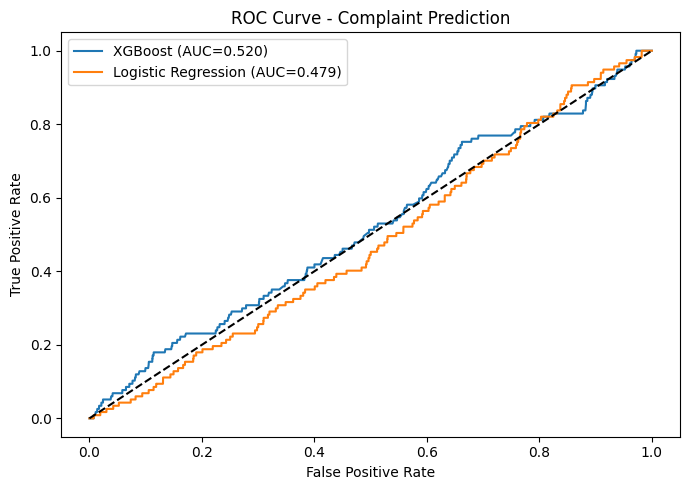

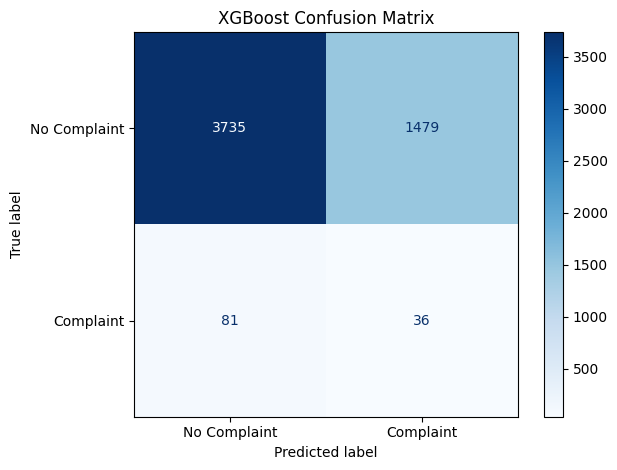

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.72      0.83      5214
           1       0.02      0.31      0.04       117

    accuracy                           0.71      5331
   macro avg       0.50      0.51      0.44      5331
weighted avg       0.96      0.71      0.81      5331



In [ ]:
# Install required libraries
!pip -q install xgboost scikit-learn matplotlib pandas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, average_precision_score
)

# Restore dataset loading
file_path = "/content/drive/MyDrive/derived_event_log_complaint_management.xlsx"
try:
    df = pd.read_excel(file_path)
    print("Dataset loaded successfully from Google Drive!")
except Exception as e:
    print(f"Could not load dataset from Drive. Error: {e}")
    print("Please upload the dataset file:")
    uploaded = files.upload()
    df = pd.read_excel(next(iter(uploaded))) if next(iter(uploaded)).endswith('.xlsx') else pd.read_csv(next(iter(uploaded)))

rows = []

for case_id, group in df.groupby("Case ID", sort=False):
    activities = group["Activity"].tolist()
    order = group[group["Event Order"] == 1]
    ready = group[group["Event Order"] == 2]

    if order.empty or ready.empty:
        continue

    order_time = order["Timestamp"].iloc[0]
    ready_time = ready["Timestamp"].iloc[0]

    prep_time = (
        (ready_time - order_time).total_seconds() / 60
        if pd.notna(order_time) and pd.notna(ready_time)
        else np.nan
    )

    ready_status = str(ready["Activity"].iloc[0])

    rows.append({
        "Case ID": case_id,
        "hour": order_time.hour if pd.notna(order_time) else np.nan,
        "weekday": order_time.dayofweek if pd.notna(order_time) else np.nan,
        "preparation_time": prep_time,
        "ready_status": ready_status,
        "complaint": int(any(a.startswith("Complaint -") for a in activities))
    })

orders = pd.DataFrame(rows)

# 3. Prepare features and target
X = orders[["hour", "weekday", "preparation_time", "ready_status"]]
X = pd.get_dummies(X, columns=["ready_status"])
X = X.fillna(X.median(numeric_only=True))
X = X.astype(float)

y = orders["complaint"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 4. Train XGBoost
scale = (y_train == 0).sum() / max((y_train == 1).sum(), 1)

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    scale_pos_weight=scale,
    eval_metric="logloss",
    random_state=42,
    n_jobs=2
)
xgb.fit(X_train, y_train)

# 5. Comparison model
lr = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)
lr.fit(X_train, y_train)

# 6. Evaluate models
plt.figure(figsize=(7, 5))

for name, model in [
    ("XGBoost", xgb),
    ("Logistic Regression", lr)
]:
    probabilities = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probabilities)
    ap = average_precision_score(y_test, probabilities)

    print(f"{name}: ROC-AUC={auc:.3f}, AP={ap:.3f}")

    fpr, tpr, _ = roc_curve(y_test, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Complaint Prediction")
plt.legend()
plt.tight_layout()
plt.savefig("complaint_roc.png", dpi=200)
plt.show()

# 7. Confusion matrix
predictions = xgb.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions,
    display_labels=["No Complaint", "Complaint"],
    cmap="Blues"
)
plt.title("XGBoost Confusion Matrix")
plt.tight_layout()
plt.savefig("complaint_confusion_matrix.png", dpi=200)
plt.show()

print("XGBoost Classification Report:")
print(classification_report(y_test, predictions, zero_division=0))

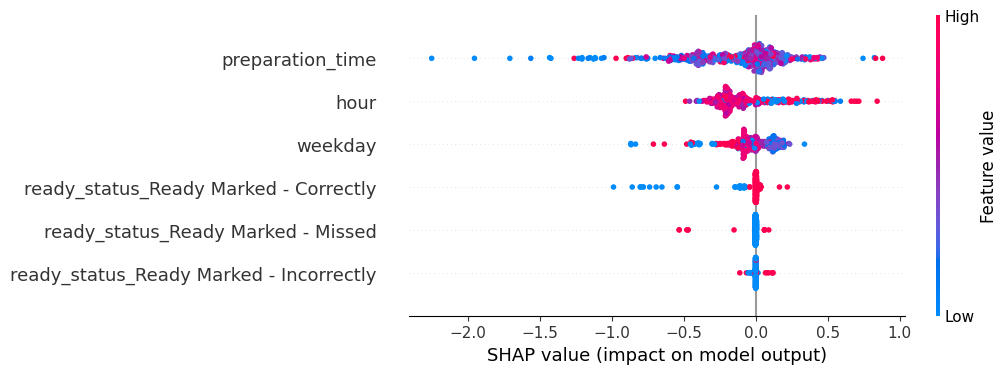

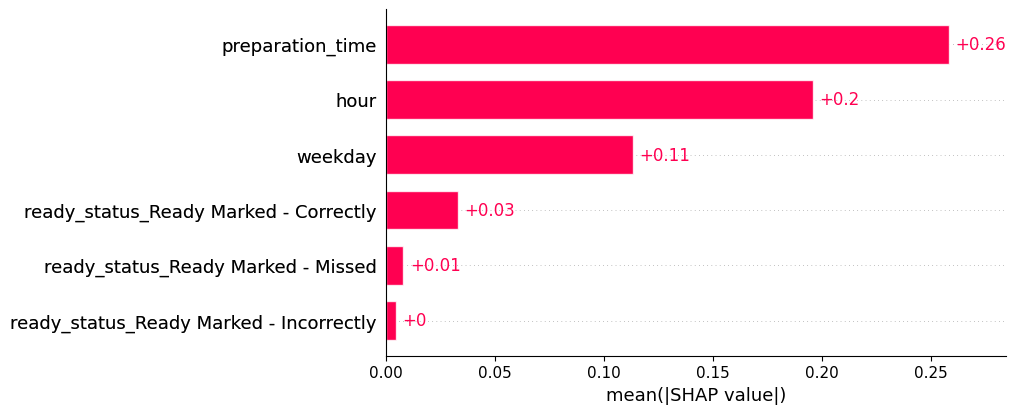

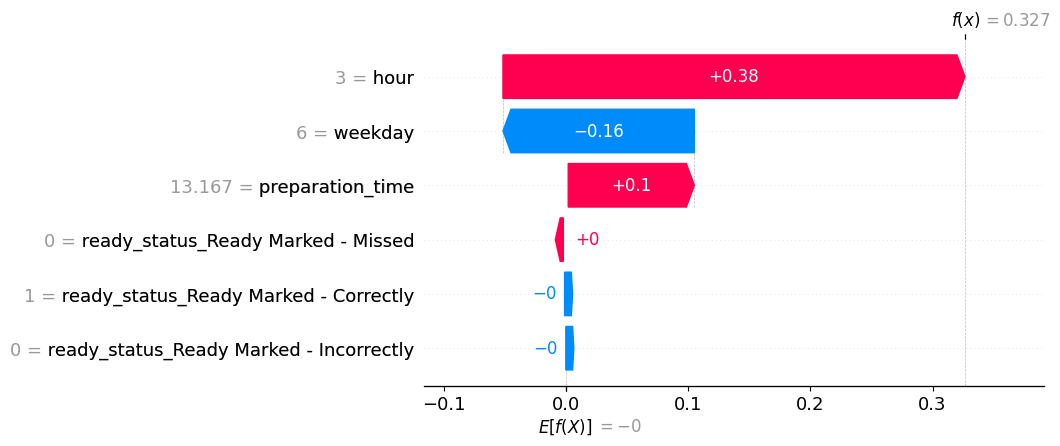

In [ ]:

!pip -q install shap

import shap
import matplotlib.pyplot as plt

# Create SHAP explainer
explainer = shap.TreeExplainer(xgb)

# Select sample
X_sample = X_test.sample(n=500, random_state=42)

# Calculate SHAP values
shap_values = explainer(X_sample)

# SHAP Beeswarm Plot
shap.plots.beeswarm(shap_values, show=False)
plt.savefig("SHAP_Beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()

# SHAP Feature Importance
shap.plots.bar(shap_values, show=False)
plt.savefig("SHAP_Feature_Importance.png", dpi=300, bbox_inches="tight")
plt.show()

# SHAP Waterfall Plot
shap.plots.waterfall(shap_values[0], show=False)
plt.savefig("SHAP_Waterfall.png", dpi=300, bbox_inches="tight")
plt.show()


Complaint cases: 469

Complaint categories:
Complaint_Type
Complaint - Non-refunded complaint              157
Complaint - Poor taste or quality               120
Complaint - Poor packaging or spillage          104
Complaint - Wrong item(s) delivered              48
Complaint - Item(s) missing or not delivered     40
Name: count, dtype: int64

Root-Cause Prediction Results
Accuracy: 0.237
Macro F1: 0.146

Classification Report:
                                              precision    recall  f1-score   support

Complaint - Item(s) missing or not delivered       0.00      0.00      0.00        10
          Complaint - Non-refunded complaint       0.31      0.45      0.37        40
      Complaint - Poor packaging or spillage       0.19      0.12      0.14        26
           Complaint - Poor taste or quality       0.21      0.23      0.22        30
         Complaint - Wrong item(s) delivered       0.00      0.00      0.00        12

                                    accuracy      

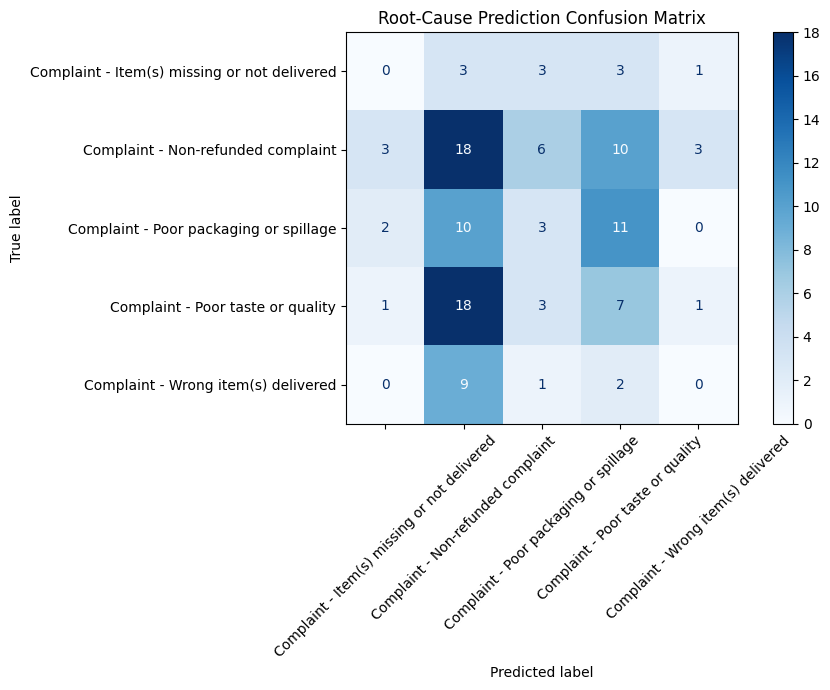


Root-Cause Model Completed!


In [ ]:
# Root-Cause Prediction Model
# XGBoost Multiclass Classification

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

# 1. Use the existing dataset
data = df.copy()

# 2. Extract complaint cases only
complaints = data[
    data["Activity"].str.startswith("Complaint -", na=False)
][["Case ID", "Activity"]].copy()

complaints = complaints.rename(
    columns={"Activity": "Complaint_Type"}
)

# 3. Use order-level operational features
features = orders.drop(
    columns=["complaint"], errors="ignore"
).copy()

# 4. Merge features with complaint types
root_data = complaints.merge(
    features,
    on="Case ID",
    how="inner"
)

print("Complaint cases:", len(root_data))
print("\nComplaint categories:")
print(root_data["Complaint_Type"].value_counts())

# 5. Prepare model inputs
X_root = root_data.drop(
    columns=["Case ID", "Complaint_Type"]
)

X_root = pd.get_dummies(
    X_root,
    columns=["ready_status"]
)

X_root = X_root.fillna(
    X_root.median(numeric_only=True)
)

X_root = X_root.astype(float)

encoder = LabelEncoder()
y_root = encoder.fit_transform(
    root_data["Complaint_Type"]
)

# 6. Split training and testing data
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_root,
    y_root,
    test_size=0.25,
    random_state=42,
    stratify=y_root
)

# 7. Train XGBoost multiclass model
root_model = XGBClassifier(
    objective="multi:softprob",
    n_estimators=150,
    max_depth=3,
    learning_rate=0.05,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=2
)

root_model.fit(Xr_train, yr_train)

# 8. Evaluate predictions
root_pred = root_model.predict(Xr_test)

print("\nRoot-Cause Prediction Results")
print("Accuracy:", round(
    accuracy_score(yr_test, root_pred), 3
))
print("Macro F1:", round(
    f1_score(
        yr_test, root_pred,
        average="macro"
    ), 3
))

print("\nClassification Report:")
print(classification_report(
    yr_test,
    root_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

# 9. Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 7))

ConfusionMatrixDisplay.from_predictions(
    yr_test,
    root_pred,
    display_labels=encoder.classes_,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("Root-Cause Prediction Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "Root_Cause_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nRoot-Cause Model Completed!")